# Cross-entropy method

Learn the cross-entropy method on discrete Taxi states, then use a neural-network policy for CartPole.

This exercise targets Python 3.12+:

```bash
python -m pip install "gymnasium[classic-control]>=1.3,<2" numpy matplotlib scikit-learn ipython
```


In [1]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import clear_output

%matplotlib inline


In [2]:
env = gym.make("Taxi-v4", render_mode="ansi")
observation, info = env.reset()
print(env.render())


+---------+
|R: | : :G|
| : | : : |
| : : : : |
| | : | : |
|Y| : |B: |
+---------+




In [3]:
n_states = env.observation_space.n
n_actions = env.action_space.n

print("n_states=%i, n_actions=%i"%(n_states,n_actions))

n_states=500, n_actions=6


# Create stochastic policy

This time our policy should be a probability distribution.

```policy[s,a] = P(take action a | in state s)```

Since we still use integer state and action representations, you can use a 2-dimensional array to represent the policy.

Please initialize policy __uniformly__, that is, probabililities of all actions should be equal.


# Initialize policy (0.5pts)

In [4]:
policy = None  # TODO: create a uniform array of shape (n_states, n_actions)
policy = np.ones((n_states, n_actions)) / n_actions
assert isinstance(policy, np.ndarray)
assert np.allclose(policy, 1.0 / n_actions)
assert np.allclose(np.sum(policy, axis=1), 1.0)
print("Ok!")


Ok!


# Play the game (0.5pts)

Just like before, but we also record all states and actions we took.

In [5]:
def generate_session(policy, t_max=10**4):
    """Return a Taxi episode's states, actions, and total reward."""
    states, actions = [], []
    total_reward = 0.0
    state, info = env.reset()

    for _ in range(t_max):
        action = np.random.choice(n_actions, p=policy[state])
        next_state, reward, terminated, truncated, info = env.step(action)

        states.append(state)
        actions.append(action)
        total_reward += reward

        state = next_state
        if terminated or truncated:
            break

    return states, actions, total_reward


In [6]:
states, actions, reward = generate_session(policy)
assert isinstance(states, list) and isinstance(actions, list)
assert len(states) == len(actions)
assert isinstance(reward, (float, np.floating))


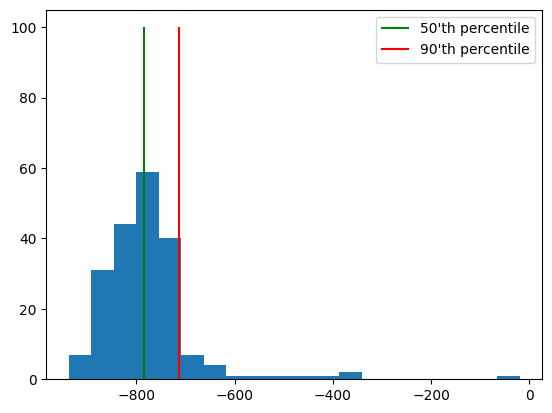

In [7]:
#let's see the initial reward distribution
import matplotlib.pyplot as plt
%matplotlib inline

sample_rewards = [generate_session(policy,t_max=1000)[-1] for _ in range(200)]

plt.hist(sample_rewards,bins=20);
plt.vlines([np.percentile(sample_rewards,50)],[0],[100],label="50'th percentile",color='green')
plt.vlines([np.percentile(sample_rewards,90)],[0],[100],label="90'th percentile",color='red')
plt.legend()

### Crossentropy method steps (1pts)

In [8]:
def select_elites(states_batch, actions_batch, rewards_batch, percentile=50):
    reward_threshold = np.percentile(rewards_batch, percentile)
    elite_states = []
    elite_actions = []

    for i in range(len(rewards_batch)):
        if rewards_batch[i] >= reward_threshold:
            for state in states_batch[i]:
                elite_states.append(state)
            for action in actions_batch[i]:
                elite_actions.append(action)

    return elite_states, elite_actions

In [9]:
states_batch = [
    [1, 2, 3],       # game 1
    [4, 2, 0, 2],    # game 2
    [3, 1],          # game 3
]
actions_batch = [
    [0, 2, 4],       # game 1
    [3, 2, 0, 1],    # game 2
    [3, 3],          # game 3
]
rewards_batch = np.array([3, 4, 5])

test_result_0 = select_elites(states_batch, actions_batch, rewards_batch, percentile=0)
test_result_30 = select_elites(states_batch, actions_batch, rewards_batch, percentile=30)
test_result_90 = select_elites(states_batch, actions_batch, rewards_batch, percentile=90)
test_result_100 = select_elites(states_batch, actions_batch, rewards_batch, percentile=100)

assert np.array_equal(test_result_0[0], [1, 2, 3, 4, 2, 0, 2, 3, 1])
assert np.array_equal(test_result_0[1], [0, 2, 4, 3, 2, 0, 1, 3, 3])
assert np.array_equal(test_result_30[0], [4, 2, 0, 2, 3, 1])
assert np.array_equal(test_result_30[1], [3, 2, 0, 1, 3, 3])
assert np.array_equal(test_result_90[0], [3, 1])
assert np.array_equal(test_result_90[1], [3, 3])
assert np.array_equal(test_result_100[0], [3, 1])
assert np.array_equal(test_result_100[1], [3, 3])
print("Ok!")


Ok!


In [10]:
def update_policy(elite_states,elite_actions):
    new_policy = np.zeros([n_states, n_actions])

    for i in range(len(elite_states)):
        state = elite_states[i]
        action = elite_actions[i]
        new_policy[state, action] += 1

    for state in range(n_states):
        total = sum(new_policy[state])
        if total == 0:
            for action in range(n_actions):
                new_policy[state, action] = 1.0 / n_actions
        else:
            for action in range(n_actions):
                new_policy[state, action] /= total

    return new_policy

In [11]:

elite_states, elite_actions = ([1, 2, 3, 4, 2, 0, 2, 3, 1], [0, 2, 4, 3, 2, 0, 1, 3, 3])


new_policy = update_policy(elite_states,elite_actions)

assert np.isfinite(new_policy).all(), "Your new policy contains NaNs or +-inf. Make sure you don't divide by zero."
assert np.all(new_policy>=0), "Your new policy can't have negative action probabilities"
assert np.allclose(new_policy.sum(axis=-1),1), "Your new policy should be a valid probability distribution over actions"
reference_answer = np.array([
       [ 1.        ,  0.        ,  0.        ,  0.        ,  0.        ],
       [ 0.5       ,  0.        ,  0.        ,  0.5       ,  0.        ],
       [ 0.        ,  0.33333333,  0.66666667,  0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        ,  0.5       ,  0.5       ]])
print(new_policy[:4,:5])
assert np.allclose(new_policy[:4,:5],reference_answer)
print("Ok!")

[[1.         0.         0.         0.         0.        ]
 [0.5        0.         0.         0.5        0.        ]
 [0.         0.33333333 0.66666667 0.         0.        ]
 [0.         0.         0.         0.5        0.5       ]]
Ok!


# Training loop (1pts)
Generate sessions, select N best and fit to those.

In [12]:
def show_progress(rewards_batch, log, percentile, reward_range=None):
    """Display the mean reward and elite threshold during training."""
    mean_reward = np.mean(rewards_batch)
    threshold = np.percentile(rewards_batch, percentile)
    log.append((mean_reward, threshold))

    clear_output(wait=True)
    print(f"mean reward = {mean_reward:.3f}, threshold = {threshold:.3f}")
    fig, axes = plt.subplots(1, 2, figsize=(9, 4))
    axes[0].plot([row[0] for row in log], label="Mean reward")
    axes[0].plot([row[1] for row in log], label="Elite threshold")
    axes[0].set_xlabel("Iteration")
    axes[0].set_ylabel("Reward")
    axes[0].legend()
    axes[0].grid(True)

    axes[1].hist(rewards_batch, bins=20, range=reward_range)
    axes[1].axvline(threshold, label="Elite threshold", color="red")
    axes[1].set_xlabel("Episode reward")
    axes[1].set_ylabel("Count")
    axes[1].legend()
    axes[1].grid(True)
    plt.tight_layout()
    plt.show()


In [13]:
# Start the training exercise with a uniform Taxi policy.
policy = np.full((n_states, n_actions), 1.0 / n_actions)


mean reward = -323.000, threshold = 6.000


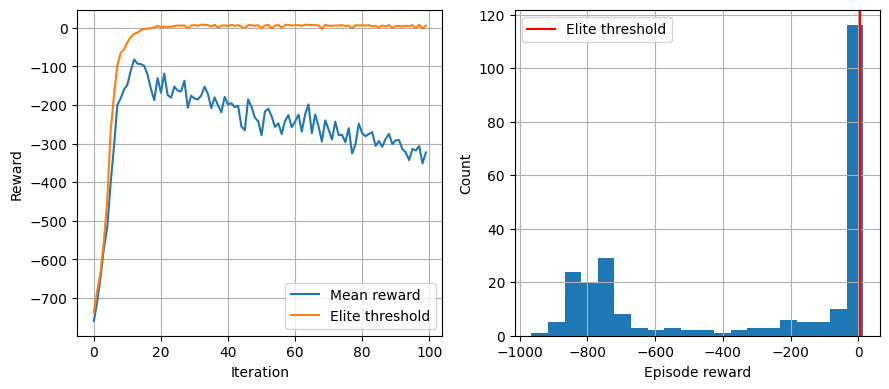

In [14]:
n_sessions = 250
percentile = 70
learning_rate = 0.5
log = []

for iteration in range(100):
    sessions = [generate_session(policy) for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile=percentile
    )
    new_policy = update_policy(elite_states, elite_actions)
    policy = learning_rate * new_policy + (1 - learning_rate) * policy
    show_progress(rewards_batch, log, percentile)


# Tabular crossentropy method

You may have noticed that the taxi problem quickly converges from -100 to a near-optimal score and then descends back into -50/-100. This is in part because the environment has some innate randomness. Namely, the starting points of passenger/driver change from episode to episode.

### Tasks
- __1.1__ (1 pts) Find out how the algorithm performance changes if you change different percentile and different n_samples. - Build graph with different percentiles on the same graph. And second one for sample size
- __1.2__ (1 pts) Tune the algorithm to end up with positive average score.

It's okay to modify the existing code.


In [15]:
env.close()
env = gym.make("Taxi-v4")
state, info = env.reset()
n_states = env.observation_space.n
n_actions = env.action_space.n
policy = np.full((n_states, n_actions), 1.0 / n_actions)

assert isinstance(policy, np.ndarray)
assert np.allclose(policy.sum(axis=1), 1.0)
states, actions, reward = generate_session(policy)
assert isinstance(states, list) and isinstance(actions, list)
assert len(states) == len(actions)
assert isinstance(reward, (float, np.floating))
step_counter = 40


In [16]:
percentiles = [50, 70, 90]
learning_rate = 0.5
mean_rewards_by_percentile = []

for percentile in percentiles:
    policy = np.ones((n_states, n_actions)) / n_actions
    current_means = []
    for iteration in range(step_counter):
        sessions = [generate_session(policy) for _ in range(n_sessions)]
        states_batch, actions_batch, rewards_batch = zip(*sessions)
        elite_states, elite_actions = select_elites(
            states_batch, actions_batch, rewards_batch, percentile=percentile
        )
        new_policy = update_policy(elite_states, elite_actions)
        policy = learning_rate * new_policy + (1 - learning_rate) * policy
        current_means.append(np.mean(rewards_batch))
    mean_rewards_by_percentile.append(current_means)

In [17]:
session_counts = [100, 250, 500]
percentile = 70
learning_rate = 0.5
mean_rewards_by_session_count = []

for n_sessions in session_counts:
    policy = np.ones((n_states, n_actions)) / n_actions
    current_means = []
    for iteration in range(step_counter):
        sessions = [generate_session(policy) for _ in range(n_sessions)]
        states_batch, actions_batch, rewards_batch = zip(*sessions)
        elite_states, elite_actions = select_elites(
            states_batch, actions_batch, rewards_batch, percentile=percentile
        )
        new_policy = update_policy(elite_states, elite_actions)
        policy = learning_rate * new_policy + (1 - learning_rate) * policy
        current_means.append(np.mean(rewards_batch))
    mean_rewards_by_session_count.append(current_means)

# Stabilize positive rewards by averaging policy across 10 games (2 pts)

In [18]:
def generate_session(policy, t_max=10**4):
    states = []
    actions = []
    total_reward = 0.0
    state, info = env.reset()

    for _ in range(t_max):
        action = np.random.choice(n_actions, p=policy[state])
        next_state, reward, terminated, truncated, info = env.step(action)

        states.append(state)
        actions.append(action)
        total_reward = total_reward + reward

        state = next_state
        if terminated or truncated:
            break

    return states, actions, total_reward

mean reward = -529.227, threshold = -113.000


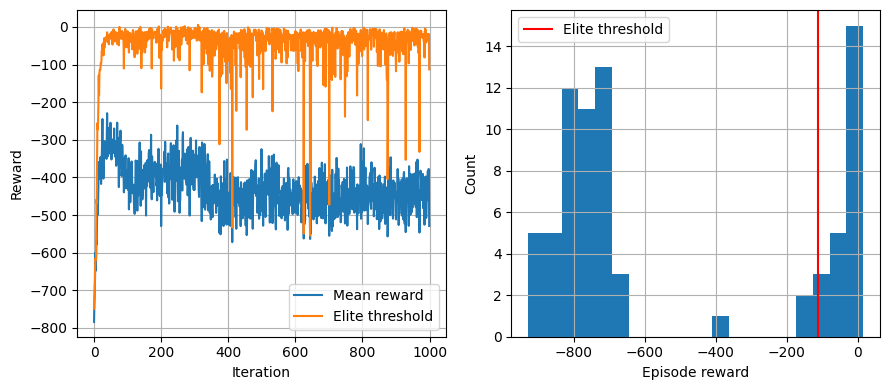

In [19]:
n_sessions = 75
percentile = 70
learning_rate = 0.2
log = []
mean = []
policy = np.full((n_states, n_actions), 1.0 / n_actions)

for iteration in range(1000):
    sessions = [generate_session(policy) for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile=percentile
    )
    new_policy = update_policy(elite_states, elite_actions)
    policy = learning_rate * new_policy + (1 - learning_rate) * policy
    show_progress(rewards_batch, log, percentile)
    if np.mean(rewards_batch) > 10:
        print("win!")
        break


Количество иттераций для достжения положительного результата возросло, но модель не только достигает большей положительной награды, но и стабильно сохраняет его.

# Digging deeper: approximate crossentropy with neural nets (2 pts)

In this section we will train a neural network policy for continuous state space game

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


(np.float64(-0.5), np.float64(599.5), np.float64(399.5), np.float64(-0.5))

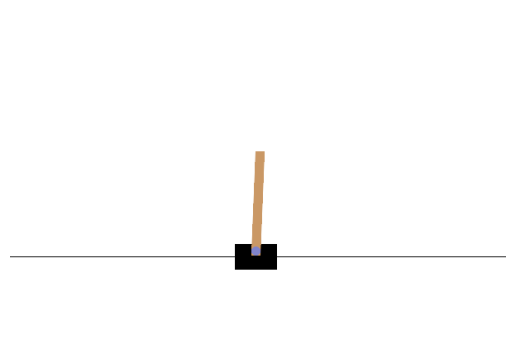

In [20]:
env.close()
env = gym.make("CartPole-v1", render_mode="rgb_array")
initial_observation, info = env.reset()
n_actions = env.action_space.n
plt.imshow(env.render())
plt.axis("off")


In [21]:
from sklearn.neural_network import MLPClassifier

agent = MLPClassifier(
    hidden_layer_sizes=(20, 20),
    activation="tanh",
    warm_start=True,
    max_iter=1,
)
initial_observation, info = env.reset()
agent.fit(
    np.repeat(initial_observation[None, :], n_actions, axis=0),
    np.arange(n_actions),
)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(


MLPClassifier(activation='tanh', hidden_layer_sizes=(20, 20), max_iter=1,
              warm_start=True)

In [22]:
def generate_session(t_max=1000):
    states = []
    actions = []
    total_reward = 0.0
    state, info = env.reset()

    for _ in range(t_max):
        probs = agent.predict_proba([state])[0]
        action = np.random.choice(n_actions, p=probs)
        next_state, reward, terminated, truncated, info = env.step(action)

        states.append(state)
        actions.append(action)
        total_reward = total_reward + reward

        state = next_state
        if terminated or truncated:
            break

    return states, actions, total_reward

In [23]:
def select_elites(states_batch, actions_batch, rewards_batch, percentile=50):
    """Select elite sessions without constructing ragged NumPy arrays."""
    threshold = np.percentile(rewards_batch, percentile)
    selected = [
        index for index, reward in enumerate(rewards_batch)
        if reward >= threshold
    ]
    elite_states = np.concatenate(
        [np.asarray(states_batch[index]) for index in selected], axis=0
    )
    elite_actions = np.concatenate(
        [np.asarray(actions_batch[index]) for index in selected], axis=0
    )
    return elite_states, elite_actions


mean reward = 197.360, threshold = 219.600


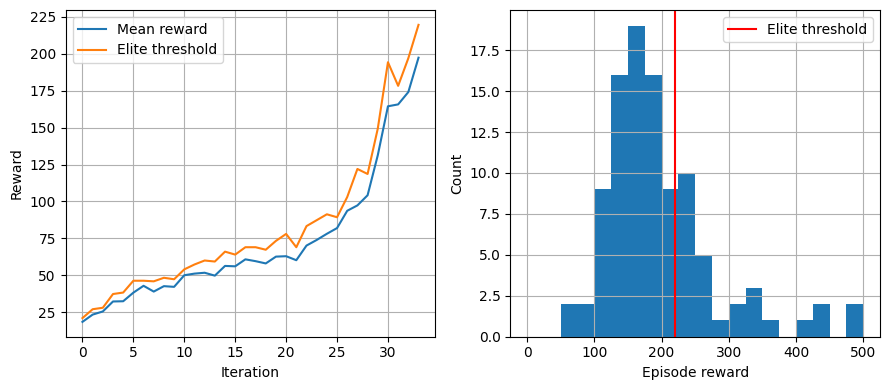

You win! You may stop training now.


In [24]:
n_sessions = 100
percentile = 70
log = []

for iteration in range(100):
    sessions = [generate_session() for _ in range(n_sessions)]
    states_batch, actions_batch, rewards_batch = zip(*sessions)
    elite_states, elite_actions = select_elites(
        states_batch, actions_batch, rewards_batch, percentile=percentile
    )
    agent.fit(elite_states, elite_actions)
    show_progress(rewards_batch, log, percentile, reward_range=(0, 500))
    if np.mean(rewards_batch) > 190:
        print("You win! You may stop training now.")
        break


# Report (1 pts)

In [28]:
# Отчет
## В ходе работы был реализован метод кросс-энтропии.
###Для Taxi использовалась табличная политика: мы записывали вероятности действий для каждого состояния в матрицу. Выяснилось, что смешивание старой и новой политики learning_rate помогает избежать резких падений награды и забывания успешного опыта.
###Для непрерывной среды CartPole табличный метод не подходит, так как состояний бесконечно много. Поэтому вместо таблицы была применена нейронная сеть MLPClassifier. Сеть успешно обучилась предсказывать правильные действия на основе элитных сессий и достигла порога победы.